In [1]:
# -------------------------------
# 1. Importing the libraries
# -------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import roc_curve, auc

In [2]:
pd.set_option('display.max_columns', None)


In [3]:
# -------------------------------
# 2. Load and sort data
# -------------------------------

df = pd.read_csv('../data/processed/housing_data_engineered.csv', parse_dates=['date'])
print("Loaded data shape:", df.shape)
df[["city","zipcode","date","downturn_risk"]].head()
id_cols = df[["date","city","zipcode"]]

Loaded data shape: (613024, 64)


In [4]:
# ----------------------------------------
# 3. Splitting the data based on date
# ----------------------------------------
cutoff_date = df["date"].quantile(0.8)
train_df = df[df["date"] <= cutoff_date].copy()
test_df  = df[df["date"] > cutoff_date].copy()


# ----------------------------------------------------
# 4. Splitting dependent and independent variables
# ----------------------------------------------------

X = df.drop(columns=["city_full"], errors="ignore")
y_train = train_df["downturn_risk"]
y_test  = test_df["downturn_risk"]

X_train = train_df.drop(columns=["downturn_risk", "date"])
X_test  = test_df.drop(columns=["downturn_risk", "date"])

In [5]:
# ----------------------------------------------------
# 5. Encoding on non-numeric columns to enable selection for the model
# ------------------------------------------------------------------

non_numeric_cols = X_train.select_dtypes(exclude=['number']).columns
X_train = pd.get_dummies(X_train, columns=non_numeric_cols, drop_first=True)
X_test  = pd.get_dummies(X_test, columns=non_numeric_cols, drop_first=True)
X_train = X_train.astype(float)
X_test  = X_test.astype(float)

In [6]:
# ----------------------------------------------------
# 6. Aligning the Train and Test datasets
# -----------------------------------------------------

X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

In [7]:
# ----------------------------------------------------
# 7. Choose the predictors based on analysis in both test and train data
# -----------------------------------------------------------------------

protected_cols = [
    "price_lag_3m",  
    "inventory_lag_3m",
    "sales_lag_3m",
    "pending_sales",
    "new_listings",
    "median_dom",
    "avg_sale_to_list",
    "price_volatility_3m",
    "price_lag_3m",
    "price_lag_6m",
    "price_ma_3m",
    "inventory_lag_3m",
    "sales_lag_3m",
    "median_list_price",
    "price",
    'sold_above_list', 
    'off_market_in_two_weeks', 'bank', 'bus', 'hospital', 'mall', 'park',
    'restaurant', 'school', 'station', 'supermarket', 
    'Total Population', 'Median Age', 
    'Per Capita Income', 'Median Rent', 'Median Home Value',
    'Unemployed Population',
]

city_cols = [c for c in X_train.columns if c.startswith("city_")]

final_cols = protected_cols + city_cols

X_train = X_train[[c for c in final_cols if c in X_train.columns]]
X_test  = X_test[[c for c in final_cols if c in X_test.columns]]



In [8]:
# ----------------------------------------------------
# 8. Choose the predictors based on Variance threshold 0.01
# -----------------------------------------------------------------------

selector = VarianceThreshold(threshold=0.01)

# fit ONLY on train
X_train_reduced_array = selector.fit_transform(X_train)

# apply same transformation to test
X_test_reduced_array = selector.transform(X_test)

# recover column names
selected_cols = X_train.columns[selector.get_support()]

# convert back to DataFrame
X_train = pd.DataFrame(X_train_reduced_array, columns=selected_cols, index=X_train.index)
X_test  = pd.DataFrame(X_test_reduced_array, columns=selected_cols, index=X_test.index)

print("Remaining features:", len(selected_cols))

Remaining features: 89


In [9]:
# ----------------------------------------------------
# 9. Scaling both test and train data
# -----------------------------------------------------------------------

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [10]:
# ----------------------------------------------------
# 10. Train the Logistic Regression model
# -----------------------------------------------------------------------


final_logreg = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    C=0.5,
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

final_logreg.fit(X_train_scaled, y_train)

LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000,
                   random_state=42)

In [11]:
# ----------------------------------------------------
# 11. Get the Prediction of Y values from test dataset
# -----------------------------------------------------------------------

y_pred = final_logreg.predict(X_test_scaled)
y_prob = final_logreg.predict_proba(X_test_scaled)[:, 1]

print("Predictions:", y_pred[:10])
print("Probabilities:", y_prob[:10])

Predictions: [1 1 1 1 0 1 0 0 1 1]
Probabilities: [0.61143878 0.76501131 0.71210193 0.68282442 0.39016844 0.50482964
 0.47716089 0.4327193  0.60470759 0.69810389]


In [12]:
# ----------------------------------------------------
# 12. Show the metrics
# -----------------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob))


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.82      0.86    101362
           1       0.38      0.56      0.45     19282

    accuracy                           0.78    120644
   macro avg       0.64      0.69      0.66    120644
weighted avg       0.82      0.78      0.80    120644


Confusion Matrix:
[[83470 17892]
 [ 8394 10888]]

ROC-AUC Score:
0.7619805560269953


In [18]:
# ----------------------------------------------------
# 13. Choose the threshold and print hte metrics again and see the improvement
# -----------------------------------------------------------------------

threshold = 0.85
y_pred = (y_prob > threshold).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob))


Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.92    101362
           1       0.60      0.20      0.30     19282

    accuracy                           0.85    120644
   macro avg       0.73      0.59      0.61    120644
weighted avg       0.82      0.85      0.82    120644


Confusion Matrix:
[[98835  2527]
 [15426  3856]]

ROC-AUC Score:
0.7619805560269953


In [19]:
# ----------------------------------------------------
# 14. Build the results and export to file
# -----------------------------------------------------------------------


id_cols = ["city", "date","zipcode"]  

id_test = test_df[id_cols].copy()

results = id_test.copy()
results["actual"] = y_test.values
results["predicted"] = y_pred
results["probability"] = y_prob

results.head()
results.to_csv("../data/result/housing_downturn_predictions.csv", index=False)

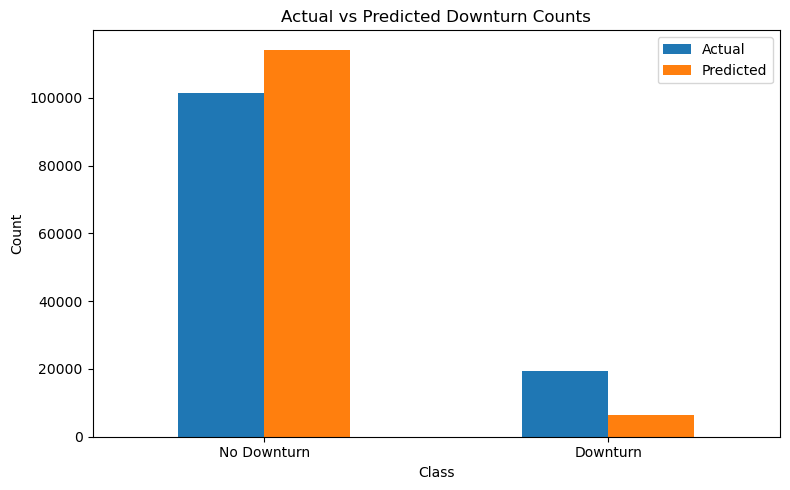

In [20]:
# ----------------------------------------------------
# 15. Bar chart on Count on Actual vs Prediction 
# -----------------------------------------------------------------------

comparison = pd.DataFrame({
    "Actual": results["actual"].value_counts().sort_index(),
    "Predicted": results["predicted"].value_counts().sort_index()
})

comparison.index = ["No Downturn", "Downturn"]

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Downturn Counts")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

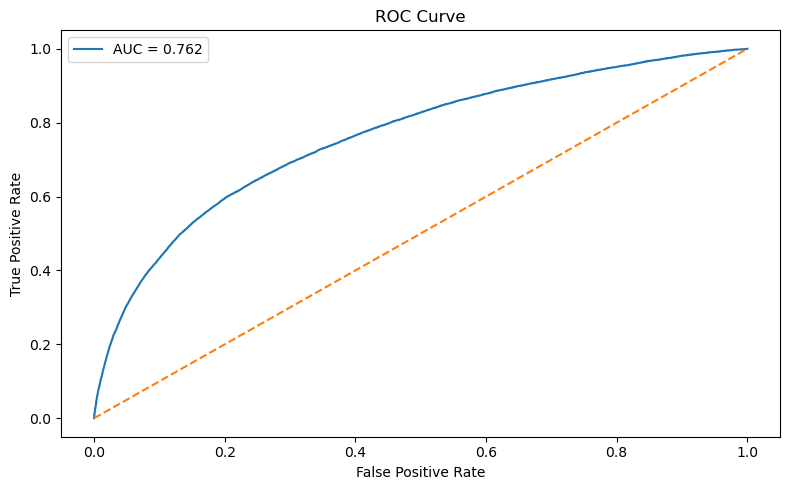

In [21]:
# ----------------------------------------------------
# 16. ROC Curve 
# -----------------------------------------------------------------------

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()